In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mplsoccer import Pitch, VerticalPitch
from mplsoccer import Pitch, FontManager, Sbopen
from matplotlib import rcParams

In [3]:
Ferran_Torres = pd.read_csv("C:/Project DATA/2026 FIFA WC Analysis/Data/wc2026_spain_vs_argentina_2026-07-19_events.csv")
Shark = Ferran_Torres[Ferran_Torres["player"] == "Ferran Torres"]

Shark.head(10)

,away_score,home_score,away_team,home_team,match_date,match_id,id,eventId,minute,second,...,qual_LowLeft,qual_VoidYellowCard,qual_FastBreak,qual_HighCentre,qual_SecondYellow,qual_HighRight,qual_HighLeft,qual_IntentionalGoalAssist,qual_GoalDisallowed,qual_LastMan
1060,0,0,Argentina,Spain,2026-07-19,2007644,2.948014e+09,647,61,10.0,...,False,False,False,False,False,False,False,False,False,False
1067,0,0,Argentina,Spain,2026-07-19,2007644,2.948014e+09,652,61,44.0,...,False,False,False,False,False,False,False,False,False,False
1135,0,0,Argentina,Spain,2026-07-19,2007644,2.948015e+09,695,66,23.0,...,False,False,False,False,False,False,False,False,False,False
1252,0,0,Argentina,Spain,2026-07-19,2007644,2.948017e+09,762,76,6.0,...,False,False,False,False,False,False,False,False,False,False
1264,0,0,Argentina,Spain,2026-07-19,2007644,2.948017e+09,770,76,34.0,...,False,False,False,False,False,False,False,False,False,False
1371,0,0,Argentina,Spain,2026-07-19,2007644,2.948018e+09,886,83,18.0,...,False,False,False,False,False,False,False,False,False,False
1394,0,0,Argentina,Spain,2026-07-19,2007644,2.948018e+09,869,84,26.0,...,False,False,False,False,False,False,False,False,False,False
1428,0,0,Argentina,Spain,2026-07-19,2007644,2.948018e+09,903,86,25.0,...,False,False,False,False,False,False,False,False,False,False
1479,0,0,Argentina,Spain,2026-07-19,2007644,2.948019e+09,985,90,0.0,...,False,False,False,False,False,False,False,False,False,False
1484,0,0,Argentina,Spain,2026-07-19,2007644,2.948018e+09,943,90,8.0,...,False,False,False,False,False,False,False,False,False,False


# Pass Map

In [3]:
Shark_Pass = Shark.loc[
    Shark["event"].isin(["Pass"]),
    ["x", "y", "endX", "endY", "outcome", "event"],
]

Shark_Pass.head(10)

,x,y,endX,endY,outcome,event
1252,77.3,69.0,71.6,81.4,Successful,Pass
1264,86.6,33.8,89.7,24.8,Successful,Pass
1394,89.5,27.7,90.6,29.7,Unsuccessful,Pass
1479,50.3,50.0,38.8,50.0,Successful,Pass
1518,80.4,26.0,77.0,16.0,Successful,Pass
1559,97.7,25.0,90.7,27.6,Successful,Pass
1669,43.6,32.6,46.4,39.2,Successful,Pass
1825,22.1,5.1,27.6,10.7,Unsuccessful,Pass
1927,53.0,59.9,43.5,67.3,Successful,Pass


In [4]:
Pass_Type = {
    "Successful": dict(color='#00ff87', headwidth=10, headlength=10, label='Successful Pass'),
    "Unsuccessful": dict(color='red', headwidth=6, headlength=5, headaxislength=12, label='Unsuccessful Pass'),
}


Text(0.5, 1.0, 'Ferran Torres Pass Map')

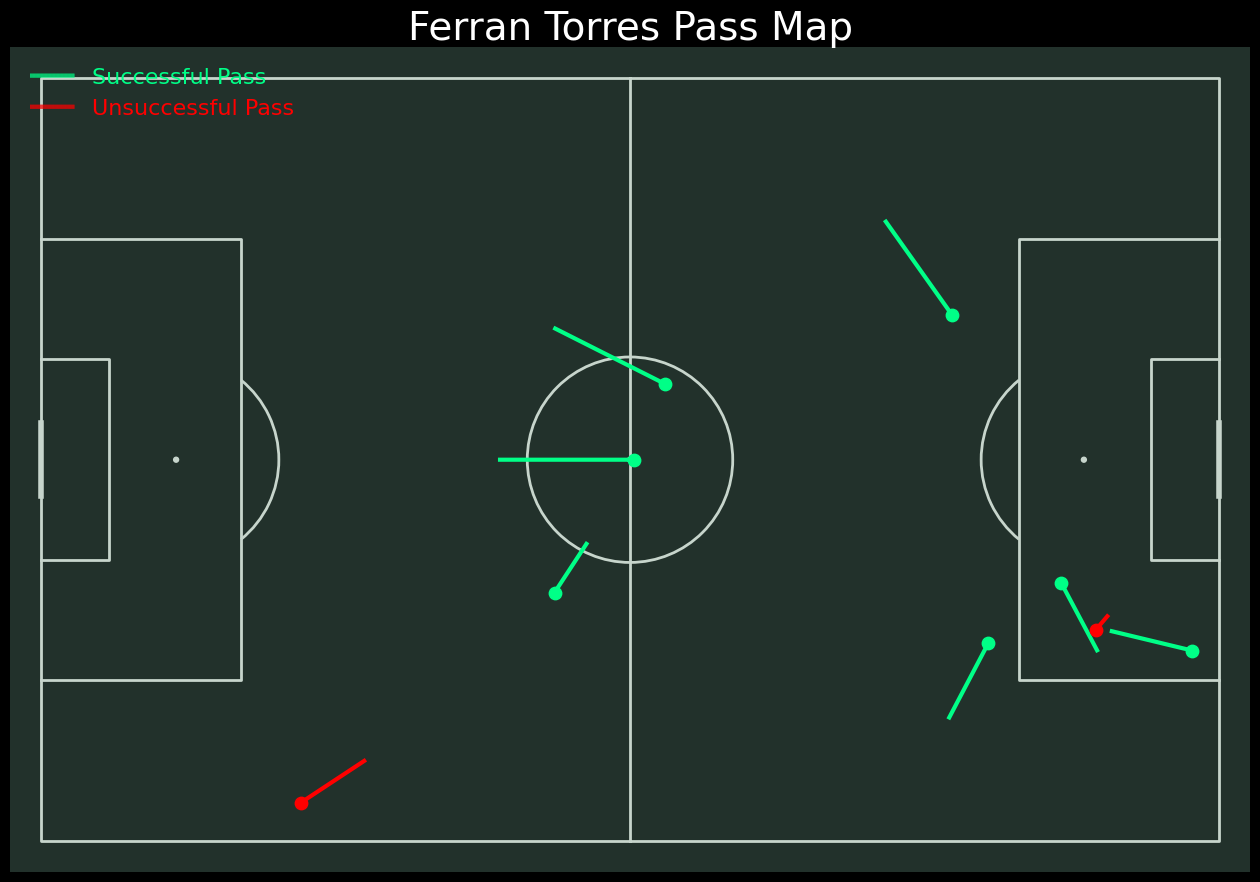

In [5]:
pitch = Pitch(pitch_type='opta', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('black')

for outcome, group in Shark_Pass.groupby("outcome"):
    style = Pass_Type[outcome]
    pitch.lines(group.x, group.y, group.endX, group.endY,
                lw=3, color=style['color'], label=style['label'], ax=ax, zorder=2)
    pitch.scatter(group.x, group.y, s=80, color=style['color'], ax=ax, zorder=3)

ax.legend(frameon=False, labelcolor='linecolor', fontsize=16, loc='upper left')
ax.set_title('Ferran Torres Pass Map', fontsize=28, color='white')

# Shot Map

In [6]:
Shark_Shot = Shark.loc[
    Shark["event"].isin(["SavedShot", "Goal", "MissedShots"]),
    ["x", "y","outcome", "event"],
]

Shark_Shot.head(10)

,x,y,outcome,event
1135,91.9,45.0,Successful,SavedShot
1428,88.3,40.1,Successful,MissedShots
1795,91.2,56.2,Successful,Goal


In [7]:
Shot_Type = {
    "Goal":   {'color': '#00ff87', 'label': 'Goal'},
    "SavedShot": {'color': 'yellow', 'label': 'Saved'},
    "MissedShots": {'color': 'red', 'label': 'Missed Shot'},
}

Text(0.5, 1.0, 'Ferran Torres Shot Map')

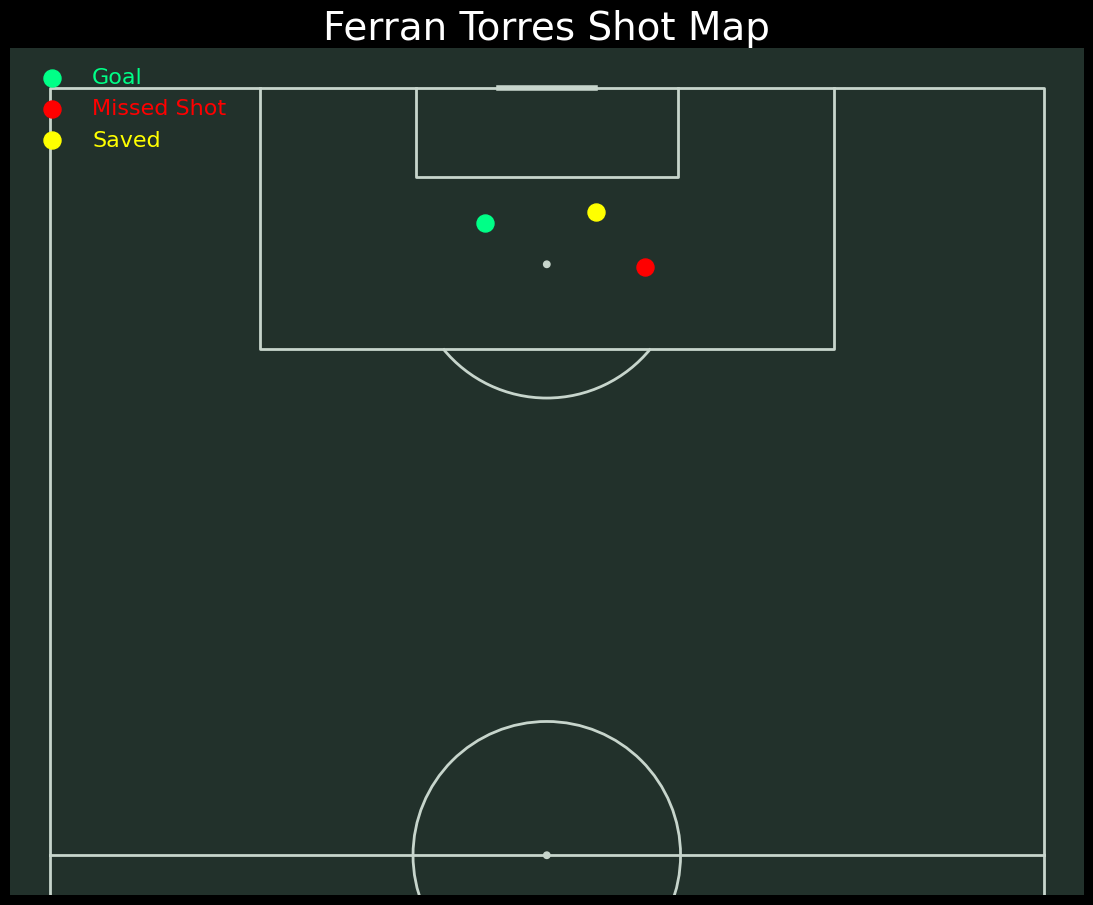

In [8]:
pitch = VerticalPitch(pitch_type='opta', pitch_color='#22312b', line_color='#c7d5cc', half=True)
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('black')

for event, group in Shark_Shot.groupby("event"):
    style = Shot_Type[event]
    pitch.scatter(group.x, group.y, s=150, color=style['color'],
                  label=style['label'], ax=ax, zorder=3)

ax.legend(frameon=False, labelcolor='linecolor', fontsize=16, loc='upper left')
ax.set_title('Ferran Torres Shot Map', fontsize=28, color='white')

# Heatmap

C:\Users\User\AppData\Local\Temp\ipykernel_23988\3908437841.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  Shark_Heatmap = sns.kdeplot(


Text(0.5, 1.0, 'Ferran Torres Heat Map')

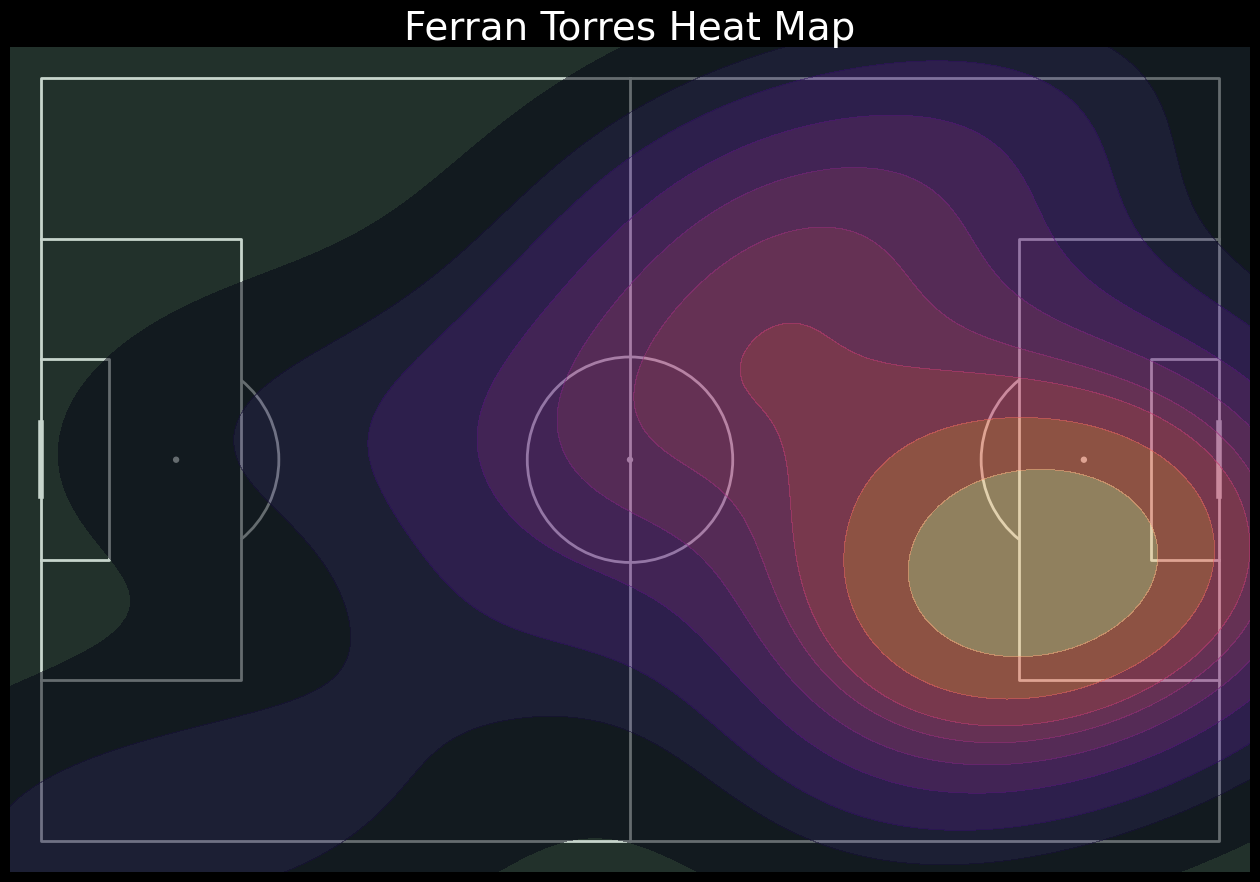

In [4]:
pitch = Pitch(pitch_type='opta', pitch_color='#22312b', line_color='#c7d5cc')
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)
fig.set_facecolor('black')

Shark_Heatmap = sns.kdeplot(
    data=Shark, x="x", y="y",
    shade=True,
    shade_lowest=False,
    alpha=.5,
    bw_adjust=1,
    n_levels=10,
    cmap="magma"
)

ax.set_title('Ferran Torres Heat Map', fontsize=28, color='white')

# Player Position Matrix